# Photometry for free: absolute magnitude and phase curve from the astrometric archive

**Question.** Every astrometric report usually carries a magnitude too. Taken together, what do
those magnitudes say about an asteroid's intrinsic brightness, its **absolute magnitude H**
(and hence its size), and about how it dims as the Sun-asteroid-observer **phase angle**
grows? And how consistent are the many surveys that reported them?

**Test case: (1036) Ganymed**, the largest near-Earth asteroid (~38 km, an Amor). Its orbit
takes it from opposition, at a phase angle of a few degrees, to close Earth passes at phase
angles above 50°, so the archive samples nearly its whole phase curve.

A PyRoOrb fit computes an observer-asteroid-Sun geometry for every observation. It converts
each magnitude to V (band corrections) and estimates H in the find_orb way: a weighted mean
under the standard H,G phase law with **G fixed at 0.15**. Here we take its per-observation
photometric residuals and go one step further, **fitting G as well**.

In [1]:
# Load the PyRoOrb settings file (.env: data folders) before the engine is imported.
from pyroorb.envfile import load_env_file
load_env_file()

import warnings
import numpy as np
import matplotlib.pyplot as plt
import pyroorb

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.0


In [2]:
desig = "1036"
obs = pyroorb.fetch_observations(desig)
fit = pyroorb.fit_orbit(obs, designation=desig)
H, sigma_H = fit.absolute_magnitude()
print(f"{len(obs)} observations, {fit.n_magnitudes()} magnitudes used for H")
print(f"PyRoOrb H = {H:.2f} +- {sigma_H:.3f}  (G fixed at {fit.slope_parameter()})")

(ASSIST) The JPL asteroid ephemeris file has not been found. Asteroid forces have been disabled.


13321 observations, 11627 magnitudes used for H
PyRoOrb H = 9.21 +- 0.001  (G fixed at 0.15)


## Reduced magnitude vs phase angle

`fit.magnitude_residuals()` gives, per observation, the phase angle α and
dMag = observed − computed. The **reduced magnitude**, the brightness the asteroid would have at
1 au from both the Sun and the observer, is then

$$V(1,1,\alpha) = H + \mathrm{dMag} - 2.5\log_{10}\Phi_{G=0.15}(\alpha),$$

with Φ the Bowell et al. (1989) H,G phase function, written out below in four lines.

In [3]:
import pandas as pd

def phi12(alpha_deg):
    t = np.tan(np.radians(alpha_deg) / 2)
    return np.exp(-3.33 * t**0.63), np.exp(-1.87 * t**1.22)

def hg_mag(alpha_deg, H, G):
    """Reduced magnitude V(1,1,alpha) of the H,G phase law."""
    p1, p2 = phi12(alpha_deg)
    return H - 2.5 * np.log10((1 - G) * p1 + G * p2)

mags = pd.DataFrame([m for m in fit.magnitude_residuals() if m["dmag"] is not None])
mags["reduced"] = H + mags.dmag + hg_mag(mags.phase_deg, 0.0, 0.15)
use = mags[mags.used & (mags.dmag.abs() < 1.5)]
print(f"{len(use)} magnitudes, phase angle {use.phase_deg.min():.1f} to {use.phase_deg.max():.1f} deg")

11480 magnitudes, phase angle 0.7 to 55.5 deg


## Fitting H and G

Survey magnitudes are noisy (0.1-0.3 mag each, plus the lightcurve), and some phase angles are
sampled thousands of times while others are sampled tens of times. So we take the **median
reduced magnitude in 2° phase bins** and fit the H,G law to those medians. The H,G law is
linear in its two Φ coefficients, so this is one `lstsq` call (in flux, with relative weights:
equivalent to equal weights in magnitude).

PyRoOrb, G fixed : H = 9.21  G = 0.15
PyRoOrb, H,G fit : H = 9.62  G = 0.46
JPL SBDB         : H = 9.17  G = 0.30
PyRoOrb, H with G held at JPL's 0.30: H = 9.44


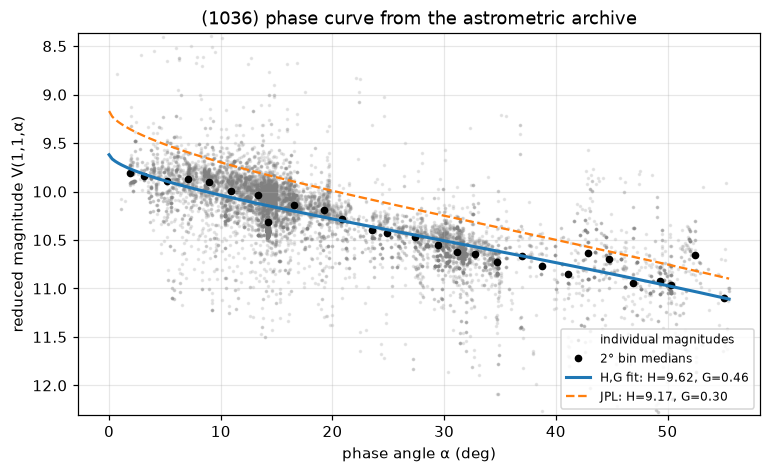

In [4]:
bins = use.assign(b=(use.phase_deg // 2) * 2 + 1).groupby("b")
binned = bins.agg(alpha=("phase_deg", "median"), R=("reduced", "median"), n=("reduced", "size"))
binned = binned[binned.n >= 10]

p1, p2 = phi12(binned.alpha.values)
flux = 10 ** (-0.4 * binned.R.values)
(a1, a2), *_ = np.linalg.lstsq(np.c_[p1, p2] / flux[:, None], np.ones(len(flux)), rcond=None)
H_fit, G_fit = -2.5 * np.log10(a1 + a2), a2 / (a1 + a2)

import json, urllib.request
pp = json.load(urllib.request.urlopen(
    f"https://ssd-api.jpl.nasa.gov/sbdb.api?sstr={desig}&phys-par=1", timeout=30))["phys_par"]
jpl = {p["name"]: float(p["value"]) for p in pp if p["name"] in ("H", "G")}
print(f"PyRoOrb, G fixed : H = {H:.2f}  G = 0.15")
print(f"PyRoOrb, H,G fit : H = {H_fit:.2f}  G = {G_fit:.2f}")
print(f"JPL SBDB         : H = {jpl['H']:.2f}  G = {jpl.get('G', float('nan')):.2f}")
H_at_jpl_G = np.median(binned.R - hg_mag(binned.alpha, 0.0, jpl["G"]))
print(f"PyRoOrb, H with G held at JPL's {jpl['G']:.2f}: H = {H_at_jpl_G:.2f}")

alpha = np.linspace(0, use.phase_deg.max(), 200)
fig, ax = plt.subplots()
ax.scatter(use.phase_deg, use.reduced, s=2, alpha=0.15, color="0.5", label="individual magnitudes")
ax.plot(binned.alpha, binned.R, "o", color="k", ms=4, label="2° bin medians")
ax.plot(alpha, hg_mag(alpha, H_fit, G_fit), lw=2, label=f"H,G fit: H={H_fit:.2f}, G={G_fit:.2f}")
ax.plot(alpha, hg_mag(alpha, jpl["H"], jpl.get("G", 0.15)), "--", lw=1.5,
        label=f"JPL: H={jpl['H']:.2f}, G={jpl.get('G', 0.15):.2f}")
ax.invert_yaxis()
ax.set_xlabel("phase angle α (deg)")
ax.set_ylabel("reduced magnitude V(1,1,α)")
ax.set_ylim(binned.R.max() + 1.2, min(H_fit, jpl["H"]) - 0.8)
ax.set_title(f"({desig}) phase curve from the astrometric archive")
ax.legend(loc="lower right", fontsize=8)
plt.show()

## How consistent are the surveys?

The residual dMag of each observation, grouped by observatory, shows each station's
*systematic* photometric offset after PyRoOrb's band-to-V conversion. These are the
differences between catalogues, filters and reduction pipelines that make archival H values
uncertain at the few-tenths-of-a-magnitude level. The station names come from the MPC
observatory-code table that ships with PyRoOrb.

,station,band,n,offset
obscode,,,,
C57,TESS,G,1417,0.36
H21,"Astronomical Research Observatory, Wes",V,896,0.16
T08,"ATLAS-MLO, Mauna Loa",Ao,821,0.01
T05,"ATLAS-HKO, Haleakala",Ao,794,-0.00
W68,"ATLAS Chile, Rio Hurtado",Ao,785,-0.01
C40,Kuban State University Astrophysical O,G,749,0.04
D04,Krasnodar,G,448,0.09
M22,"ATLAS South Africa, Sutherland",Ao,398,-0.00
703,University of Arizona Catalina Sky Sur,G,309,0.13


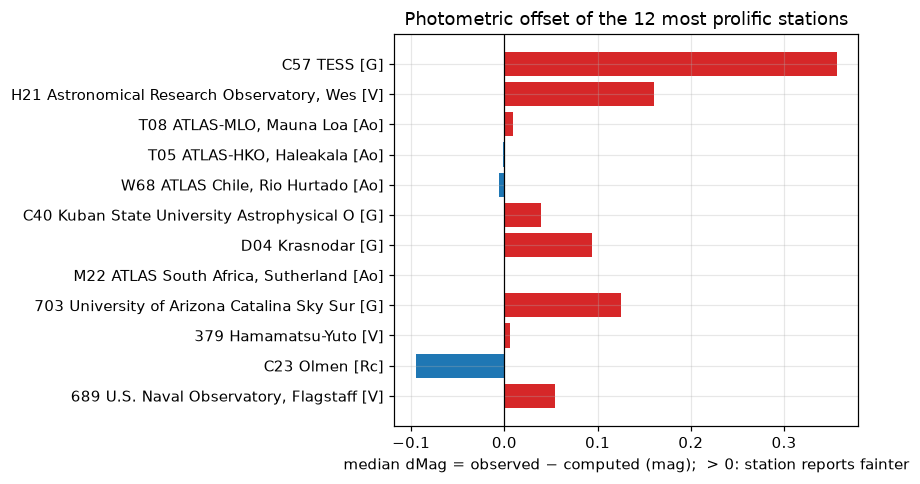

In [5]:
from importlib.resources import files
names = {}
for line in (files("pyroorb") / "package_data" / "ObsCodes.htm").read_text().splitlines():
    if len(line) > 30 and line[3] == " ":
        names[line[:3]] = line[30:].strip()

by_station = (mags[mags.used].groupby("obscode")
              .agg(n=("dmag", "size"), offset=("dmag", "median"),
                   band=("band", lambda s: s.value_counts().index[0]))
              .sort_values("n", ascending=False).head(12))
by_station["station"] = [names.get(c, "?")[:38] for c in by_station.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
lbl = [f"{c} {s} [{b}]" for c, s, b in zip(by_station.index, by_station.station, by_station.band)]
ax.barh(lbl[::-1], by_station.offset[::-1], color=np.where(by_station.offset[::-1] > 0, "C3", "C0"))
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("median dMag = observed − computed (mag);  > 0: station reports fainter")
ax.set_title("Photometric offset of the 12 most prolific stations")
fig.tight_layout()
by_station[["station", "band", "n", "offset"]].round(2)

## Takeaways

* A plain orbit fit already yields an absolute magnitude. With a few lines more, the
  same archive gives the **phase curve and the slope parameter G**, with no dedicated
  photometric campaign.
* PyRoOrb's default H (G fixed at 0.15) reproduces JPL's catalogue H to a few hundredths of a
  magnitude.
* The **fitted** phase curve tells a different story. The archive prefers a shallower phase
  curve (G ≈ 0.4) and an H about **0.4 mag fainter** than the catalogue value. Even with G held
  at JPL's 0.30 it is still ~0.3 mag fainter, so the difference is not only in G. Catalogue H
  values that are too bright by a few tenths of a magnitude are a known problem
  (Pravec et al. 2012, *Icarus* 221, 365), and they matter: 0.3 mag in H is a ~15% error in
  diameter. Two other asteroids, (433) Eros and (65803) Didymos, show the same pattern.
* The largest offset, TESS (C57, +0.36 mag), is a space telescope with a very broad red
  bandpass whose magnitudes arrive coded as band G. A generic band-to-V shift evidently does
  not fit it.
* The station offsets show how much survey photometry disagrees: **±0.1-0.35 mag** between
  stations after band conversion. A fit of this kind is only as good as the mix of
  surveys feeding it.

**Caveats.** Archival survey magnitudes are not calibrated photometry. They mix catalogues and
filters, sample random rotational phases of the lightcurve, and come with no per-observation
uncertainty. Treat an archival H as good to a few tenths of a magnitude, not to the
hundredths a formal sigma suggests. That includes the H,G fit above, which is a
demonstration of the method, not a calibrated measurement. PyRoOrb's default H assumes G = 0.15 for every asteroid,
so when the true G differs much from 0.15, that H shifts with the object's phase-angle
coverage.